# 10 — Final Model Evaluation and Selection
**Project: Retinopathy Detection System**

This notebook consolidates the four trained candidates:

1. EfficientNetB3
2. MobileNetV2
3. Hybrid EfficientNetB3 + MobileNetV2
4. Optimized hybrid with class-aware focal loss

It compares saved validation metrics, class-wise performance, confusion matrices, model size and inference latency where available. It then selects a candidate using a transparent multi-metric rule and copies it to a clearly named final-model path.

**Important evaluation limitation:** These models have been compared using the same 733-image validation split, and that split has already influenced model development. The results are therefore validation/model-selection results, not an independent final test. The public dataset test labels are unavailable. Do not describe these numbers as independent test accuracy or clinical performance.

The 85% accuracy target is not guaranteed. This notebook reports measured results honestly and does not retrain models or modify the validation split.

## 1. Imports and reproducibility

In [3]:
import os, json, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.16.1
GPU devices: []


## 2. Project paths and required artifacts

In [4]:
PROJECT_ROOT = Path(r"S:\ISP")
DATA_ROOT = PROJECT_ROOT / "data"
MODEL_DIR = DATA_ROOT / "processed" / "models"
RESULT_DIR = DATA_ROOT / "processed" / "results"
FINAL_DIR = DATA_ROOT / "processed" / "final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

candidate_models = {
    "EfficientNetB3": MODEL_DIR / "efficientnetb3_final.keras",
    "MobileNetV2": MODEL_DIR / "mobilenetv2_final.keras",
    "Hybrid": MODEL_DIR / "hybrid_efficientnetb3_mobilenetv2_final.keras",
    "Hybrid_Focal_Optimized": MODEL_DIR / "hybrid_optimized_focal.keras"
}

metric_files = {
    "EfficientNetB3": RESULT_DIR / "efficientnetb3_validation_results.json",
    "MobileNetV2": RESULT_DIR / "mobilenetv2_validation_results.json",
    "Hybrid": RESULT_DIR / "hybrid_validation_results.json",
    "Hybrid_Focal_Optimized": RESULT_DIR / "hybrid_optimized_focal_results.json"
}

for name, path in candidate_models.items():
    print(f"{name:25s} model exists: {path.exists()} | {path}")
for name, path in metric_files.items():
    print(f"{name:25s} metrics exist: {path.exists()} | {path}")

if not any(p.exists() for p in candidate_models.values()):
    raise FileNotFoundError("No candidate .keras models found. Check MODEL_DIR.")

EfficientNetB3            model exists: True | S:\ISP\data\processed\models\efficientnetb3_final.keras
MobileNetV2               model exists: True | S:\ISP\data\processed\models\mobilenetv2_final.keras
Hybrid                    model exists: True | S:\ISP\data\processed\models\hybrid_efficientnetb3_mobilenetv2_final.keras
Hybrid_Focal_Optimized    model exists: True | S:\ISP\data\processed\models\hybrid_optimized_focal.keras
EfficientNetB3            metrics exist: True | S:\ISP\data\processed\results\efficientnetb3_validation_results.json
MobileNetV2               metrics exist: True | S:\ISP\data\processed\results\mobilenetv2_validation_results.json
Hybrid                    metrics exist: True | S:\ISP\data\processed\results\hybrid_validation_results.json
Hybrid_Focal_Optimized    metrics exist: True | S:\ISP\data\processed\results\hybrid_optimized_focal_results.json


## 3. Load the saved validation split and check consistency

In [5]:
VAL_SPLIT = RESULT_DIR / "efficientnetb3_validation_split.csv"
if not VAL_SPLIT.exists():
    raise FileNotFoundError(f"Validation split not found: {VAL_SPLIT}")

val_df = pd.read_csv(VAL_SPLIT)
val_df["id_code"] = val_df["id_code"].astype(str)
val_df["diagnosis"] = pd.to_numeric(val_df["diagnosis"]).astype(int)

if not val_df["diagnosis"].between(0, 4).all():
    raise ValueError("Expected class labels 0 through 4.")

print("Validation image count:", len(val_df))
display(val_df["diagnosis"].value_counts().sort_index().to_frame("count"))

Validation image count: 733


,count
diagnosis,
0,361
1,74
2,200
3,39
4,59


## 4. Load all available metric JSON files

In [6]:
metric_rows = []
metric_data = {}

for name, path in metric_files.items():
    if not path.exists():
        print("Missing metrics file:", path.name)
        continue

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    metric_data[name] = data
    metric_rows.append({
        "Model": name,
        "Accuracy": data.get("accuracy", np.nan),
        "Macro Precision": data.get("macro_precision", np.nan),
        "Macro Recall": data.get("macro_recall", np.nan),
        "Macro F1": data.get("macro_f1", np.nan),
        "QWK": data.get("quadratic_weighted_kappa", np.nan),
        "Validation Images": data.get("validation_images", len(val_df))
    })

metrics_df = pd.DataFrame(metric_rows)
if metrics_df.empty:
    raise FileNotFoundError("No validation metric JSON files were found.")
display(metrics_df.round(4))
metrics_df.to_csv(RESULT_DIR / "final_model_metrics_comparison.csv", index=False)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,QWK,Validation Images
0,EfficientNetB3,0.7408,0.5980,0.6032,0.5735,0.8370,733
1,MobileNetV2,0.6658,0.4991,0.5396,0.4925,0.7699,733
2,Hybrid,0.7694,0.6164,0.6516,0.6253,0.8423,733
3,Hybrid_Focal_Optimized,0.7817,0.6281,0.6360,0.6284,0.8476,733


## 5. Add model size and measured inference latency

In [7]:
efficiency_files = {
    "EfficientNetB3": RESULT_DIR / "efficientnetb3_efficiency.json",
    "MobileNetV2": RESULT_DIR / "mobilenetv2_efficiency.json",
    "Hybrid": RESULT_DIR / "hybrid_efficiency.json"
}

eff_rows = []
for name, path in efficiency_files.items():
    if path.exists():
        with open(path, "r", encoding="utf-8") as f:
            d = json.load(f)
        eff_rows.append({
            "Model": name,
            "Model Size (MB)": d.get("model_size_mb", np.nan),
            "Inference Latency (ms/image)": d.get(
                "mean_single_image_inference_ms",
                d.get("inference_latency_ms", d.get("latency_ms", np.nan))
            )
        })
    else:
        print("Efficiency file not found:", path.name)

eff_df = pd.DataFrame(eff_rows)
if not eff_df.empty:
    metrics_df = metrics_df.merge(eff_df, on="Model", how="left")
else:
    metrics_df["Model Size (MB)"] = np.nan
    metrics_df["Inference Latency (ms/image)"] = np.nan

# Ensure model size is available for every existing checkpoint, including the optimized model.
for idx, row in metrics_df.iterrows():
    model_path = candidate_models.get(row["Model"])
    if model_path and model_path.exists():
        metrics_df.loc[idx, "Model Size (MB)"] = model_path.stat().st_size / (1024**2)

display(metrics_df.round(4))
metrics_df.to_csv(RESULT_DIR / "final_model_metrics_comparison.csv", index=False)

Efficiency file not found: efficientnetb3_efficiency.json


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,QWK,Validation Images,Model Size (MB),Inference Latency (ms/image)
0,EfficientNetB3,0.7408,0.5980,0.6032,0.5735,0.8370,733,69.4951,NaN
1,MobileNetV2,0.6658,0.4991,0.5396,0.4925,0.7699,733,22.8936,111.6131
2,Hybrid,0.7694,0.6164,0.6516,0.6253,0.8423,733,120.9969,420.5854
3,Hybrid_Focal_Optimized,0.7817,0.6281,0.6360,0.6284,0.8476,733,120.9786,NaN


## 6. Visualize accuracy and macro F1 comparison

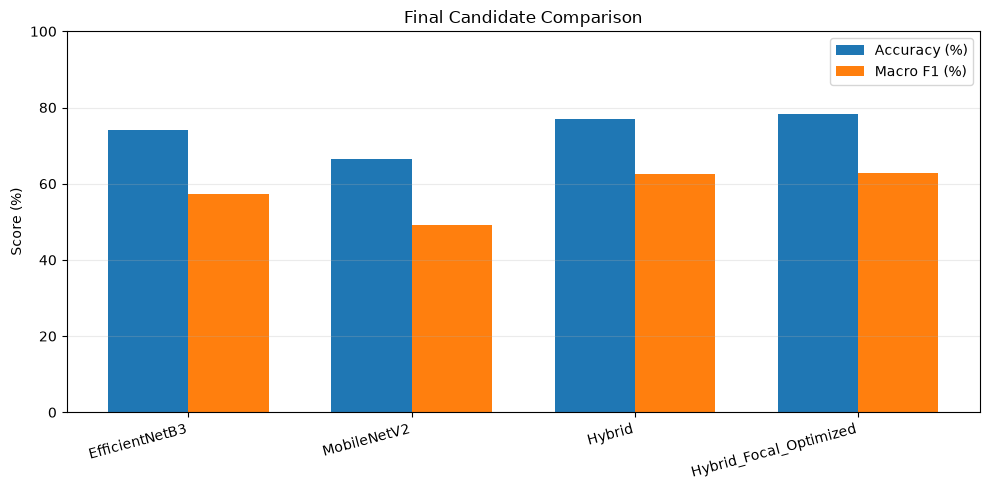

In [8]:
plot_df = metrics_df.dropna(subset=["Accuracy"]).copy()
if len(plot_df):
    x = np.arange(len(plot_df))
    width = 0.36
    plt.figure(figsize=(10, 5))
    plt.bar(x - width/2, plot_df["Accuracy"] * 100, width, label="Accuracy (%)")
    plt.bar(x + width/2, plot_df["Macro F1"] * 100, width, label="Macro F1 (%)")
    plt.xticks(x, plot_df["Model"], rotation=15, ha="right")
    plt.ylabel("Score (%)")
    plt.title("Final Candidate Comparison")
    plt.ylim(0, 100)
    plt.grid(axis="y", alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULT_DIR / "final_model_metrics_comparison.png", dpi=200)
    plt.show()

## 7. Inspect available saved classification reports

In [9]:
report_paths = {
    "EfficientNetB3": RESULT_DIR / "efficientnetb3_classification_report.csv",
    "MobileNetV2": RESULT_DIR / "mobilenetv2_classification_report.csv",
    "Hybrid": RESULT_DIR / "hybrid_classification_report.csv",
    "Hybrid_Focal_Optimized": RESULT_DIR / "hybrid_optimized_focal_classification_report.csv"
}

class_rows = []
for name, path in report_paths.items():
    if not path.exists():
        print("Classification report missing:", path.name)
        continue
    report = pd.read_csv(path, index_col=0)
    for class_id in ["0", "1", "2", "3", "4"]:
        if class_id in report.index:
            class_rows.append({
                "Model": name,
                "Class": int(class_id),
                "Precision": report.loc[class_id, "precision"],
                "Recall": report.loc[class_id, "recall"],
                "F1": report.loc[class_id, "f1-score"],
                "Support": report.loc[class_id, "support"]
            })

class_df = pd.DataFrame(class_rows)
if not class_df.empty:
    display(class_df.round(4))
    class_df.to_csv(RESULT_DIR / "final_classwise_comparison.csv", index=False)

,Model,Class,Precision,Recall,F1,Support
0,MobileNetV2,0,0.9440,0.9335,0.9387,361.0
1,MobileNetV2,1,0.3621,0.5676,0.4421,74.0
2,MobileNetV2,2,0.6832,0.3450,0.4585,200.0
3,MobileNetV2,3,0.2326,0.5128,0.3200,39.0
4,MobileNetV2,4,0.2740,0.3390,0.3030,59.0
5,Hybrid,0,0.9744,0.9474,0.9607,361.0
6,Hybrid,1,0.4312,0.6351,0.5137,74.0
7,Hybrid,2,0.7750,0.6200,0.6889,200.0
8,Hybrid,3,0.3929,0.5641,0.4632,39.0
9,Hybrid,4,0.5088,0.4915,0.5000,59.0


## 8. Plot per-class F1 for available reports

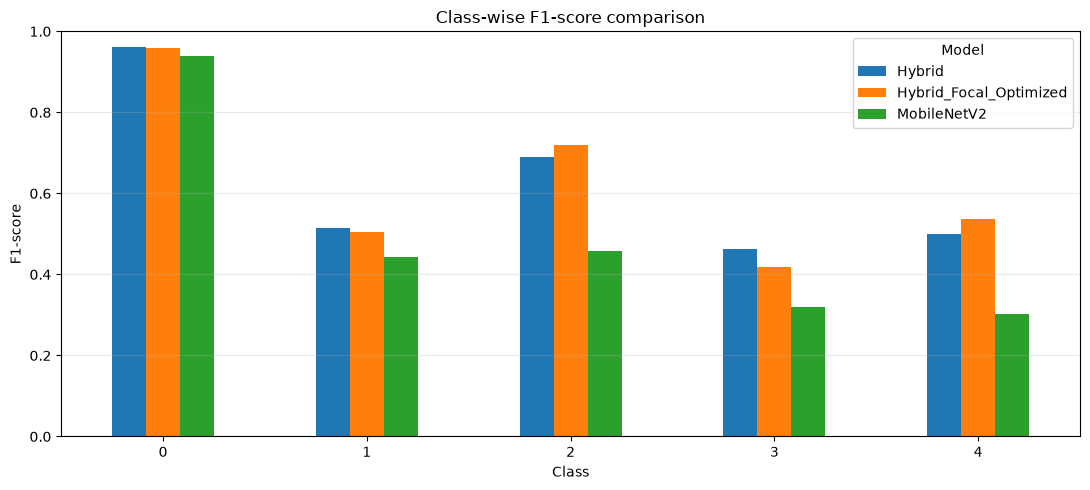

In [10]:
if not class_df.empty:
    pivot_f1 = class_df.pivot(index="Class", columns="Model", values="F1")
    ax = pivot_f1.plot(kind="bar", figsize=(11, 5))
    ax.set_title("Class-wise F1-score comparison")
    ax.set_xlabel("Class")
    ax.set_ylabel("F1-score")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(RESULT_DIR / "final_classwise_f1_comparison.png", dpi=200)
    plt.show()

## 9. Compare confusion matrices when saved

Prediction CSV not found: efficientnetb3_predictions.csv

Confusion matrices calculated: 3


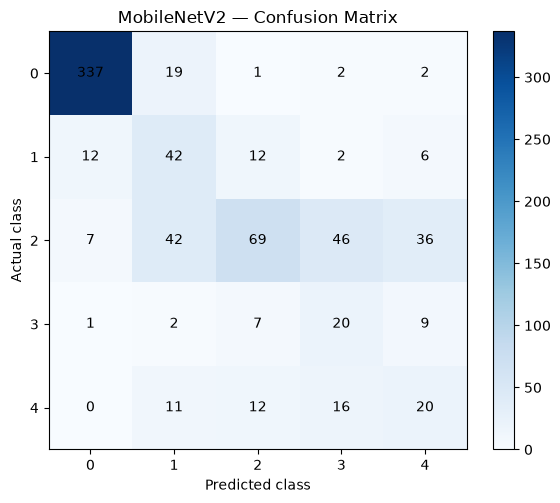

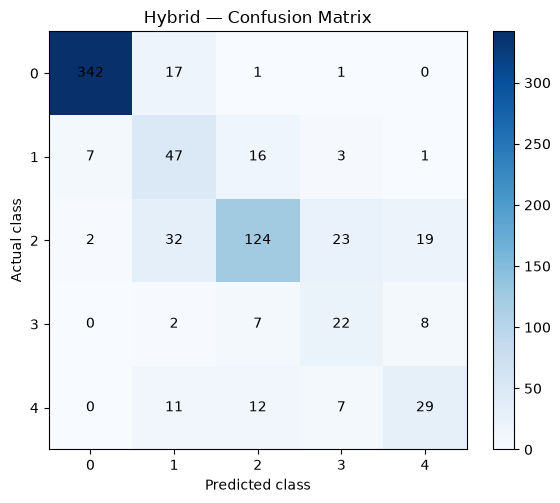

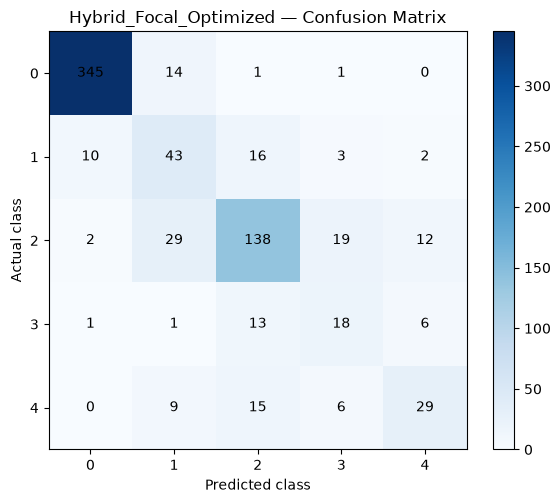


Section 9 completed successfully.


In [11]:

# SECTION 9 — Compare confusion matrices safely
# Recalculate 5x5 matrices from prediction CSV files.
# This avoids loading large PNG images into memory.

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

prediction_paths = {
    "EfficientNetB3": RESULT_DIR / "efficientnetb3_predictions.csv",
    "MobileNetV2": RESULT_DIR / "mobilenetv2_predictions.csv",
    "Hybrid": RESULT_DIR / "hybrid_predictions.csv",
    "Hybrid_Focal_Optimized": RESULT_DIR / "hybrid_optimized_focal_predictions.csv"
}

available_predictions = []

for name, path in prediction_paths.items():
    if not path.exists():
        print("Prediction CSV not found:", path.name)
        continue

    pred_df = pd.read_csv(path)

    actual_col = (
        "actual" if "actual" in pred_df.columns
        else "diagnosis" if "diagnosis" in pred_df.columns
        else None
    )
    predicted_col = "predicted" if "predicted" in pred_df.columns else None

    if actual_col is None or predicted_col is None:
        print("Required columns missing:", path.name)
        print("Available columns:", list(pred_df.columns))
        continue

    y_actual = pred_df[actual_col].astype(int).to_numpy()
    y_predicted = pred_df[predicted_col].astype(int).to_numpy()

    cm = confusion_matrix(
        y_actual,
        y_predicted,
        labels=[0, 1, 2, 3, 4]
    )

    available_predictions.append((name, cm))

print("\nConfusion matrices calculated:", len(available_predictions))

# Plot one small 5x5 matrix per model.
for name, cm in available_predictions:

    fig, ax = plt.subplots(figsize=(6, 5))

    image = ax.imshow(cm, cmap="Blues")

    ax.set_title(name + " — Confusion Matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.set_xticks(range(5))
    ax.set_yticks(range(5))

    for i in range(5):
        for j in range(5):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center")

    fig.colorbar(image, ax=ax)
    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_")
    fig.savefig(
        RESULT_DIR / f"{safe_name}_final_confusion_matrix.png",
        dpi=120,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nSection 9 completed successfully.")


## 10. Validate saved prediction files and calculate metrics consistently

In [12]:
prediction_paths = {
    "EfficientNetB3": RESULT_DIR / "efficientnetb3_predictions.csv",
    "MobileNetV2": RESULT_DIR / "mobilenetv2_predictions.csv",
    "Hybrid": RESULT_DIR / "hybrid_predictions.csv",
    "Hybrid_Focal_Optimized": RESULT_DIR / "hybrid_optimized_focal_predictions.csv"
}

recomputed_rows = []
for name, path in prediction_paths.items():
    if not path.exists():
        print("Prediction file missing:", path.name)
        continue

    pred = pd.read_csv(path)
    actual_col = "actual" if "actual" in pred.columns else (
        "diagnosis" if "diagnosis" in pred.columns else None
    )
    predicted_col = "predicted" if "predicted" in pred.columns else None

    if actual_col is None or predicted_col is None:
        print("Cannot identify actual/predicted columns in", path.name)
        continue

    if len(pred) != len(val_df):
        print(f"Warning: {name} predictions have {len(pred)} rows; validation has {len(val_df)}.")
        continue

    yt = pred[actual_col].to_numpy(dtype=int)
    yp = pred[predicted_col].to_numpy(dtype=int)
    recomputed_rows.append({
        "Model": name,
        "Accuracy from CSV": accuracy_score(yt, yp),
        "Macro Precision from CSV": precision_score(yt, yp, average="macro", zero_division=0),
        "Macro Recall from CSV": recall_score(yt, yp, average="macro", zero_division=0),
        "Macro F1 from CSV": f1_score(yt, yp, average="macro", zero_division=0),
        "QWK from CSV": cohen_kappa_score(yt, yp, weights="quadratic")
    })

recomputed_df = pd.DataFrame(recomputed_rows)
if not recomputed_df.empty:
    display(recomputed_df.round(4))
    recomputed_df.to_csv(RESULT_DIR / "final_recomputed_metrics_from_predictions.csv", index=False)

Prediction file missing: efficientnetb3_predictions.csv


,Model,Accuracy from CSV,Macro Precision from CSV,Macro Recall from CSV,Macro F1 from CSV,QWK from CSV
0,MobileNetV2,0.6658,0.4991,0.5396,0.4925,0.7699
1,Hybrid,0.7694,0.6164,0.6516,0.6253,0.8423
2,Hybrid_Focal_Optimized,0.7817,0.6281,0.6360,0.6284,0.8476


## 11. Select the candidate using a transparent rule

In [13]:
# Selection rule:
# 1) Highest QWK, because the five output labels are ordinal.
# 2) If QWK is missing/tied, higher macro F1.
# 3) If still tied, higher accuracy.
# This is a model-selection rule on an already-used validation set, not independent testing.

selection_df = metrics_df.dropna(subset=["Accuracy"]).copy()
if selection_df.empty:
    raise ValueError("No candidate with an accuracy metric is available.")

for col in ["QWK", "Macro F1", "Accuracy"]:
    selection_df[col] = pd.to_numeric(selection_df[col], errors="coerce")

selection_df = selection_df.sort_values(
    by=["QWK", "Macro F1", "Accuracy"],
    ascending=[False, False, False],
    na_position="last"
)
display(selection_df[["Model", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "QWK"]].round(4))

selected_name = selection_df.iloc[0]["Model"]
selected_source = candidate_models[selected_name]
if not selected_source.exists():
    raise FileNotFoundError(f"Selected checkpoint does not exist: {selected_source}")

print("Selected candidate:", selected_name)
print("Source checkpoint:", selected_source)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,QWK
3,Hybrid_Focal_Optimized,0.7817,0.6281,0.6360,0.6284,0.8476
2,Hybrid,0.7694,0.6164,0.6516,0.6253,0.8423
0,EfficientNetB3,0.7408,0.5980,0.6032,0.5735,0.8370
1,MobileNetV2,0.6658,0.4991,0.5396,0.4925,0.7699


Selected candidate: Hybrid_Focal_Optimized
Source checkpoint: S:\ISP\data\processed\models\hybrid_optimized_focal.keras


## 12. Copy selected checkpoint to the final model folder

In [14]:
FINAL_MODEL_PATH = FINAL_DIR / "retinopathy_detection_final_model.keras"
shutil.copy2(selected_source, FINAL_MODEL_PATH)

selection_record = {
    "selected_model": str(selected_name),
    "source_checkpoint": str(selected_source),
    "final_checkpoint": str(FINAL_MODEL_PATH),
    "selection_rule": "Highest QWK, then macro F1, then accuracy",
    "validation_accuracy": float(selection_df.iloc[0]["Accuracy"]),
    "validation_macro_f1": float(selection_df.iloc[0]["Macro F1"]),
    "validation_qwk": float(selection_df.iloc[0]["QWK"]),
    "evaluation_note": (
        "Validation/model-selection result. The same validation split was used "
        "during development; this is not an independent test result."
    )
}
with open(FINAL_DIR / "final_model_selection.json", "w", encoding="utf-8") as f:
    json.dump(selection_record, f, indent=4)

print("Final candidate copied successfully.")
print("Final model:", FINAL_MODEL_PATH)
print(json.dumps(selection_record, indent=4))

Final candidate copied successfully.
Final model: S:\ISP\data\processed\final\retinopathy_detection_final_model.keras
{
    "selected_model": "Hybrid_Focal_Optimized",
    "source_checkpoint": "S:\\ISP\\data\\processed\\models\\hybrid_optimized_focal.keras",
    "final_checkpoint": "S:\\ISP\\data\\processed\\final\\retinopathy_detection_final_model.keras",
    "selection_rule": "Highest QWK, then macro F1, then accuracy",
    "validation_accuracy": 0.781718963165075,
    "validation_macro_f1": 0.6283633752109191,
    "validation_qwk": 0.8475681056553859,
    "evaluation_note": "Validation/model-selection result. The same validation split was used during development; this is not an independent test result."
}


## 13. Load the final checkpoint and verify its predictions

In [15]:
# compile=False supports checkpoints saved with a custom loss function.
final_model = tf.keras.models.load_model(FINAL_MODEL_PATH, compile=False)
print("Final checkpoint loaded.")
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)

Final checkpoint loaded.
Input shape: (None, 300, 300, 3)
Output shape: (None, 5)


## 14. Measure final model size and inference latency

In [16]:
final_size_mb = FINAL_MODEL_PATH.stat().st_size / (1024**2)
latency_ms = None

# Latency is measured only if the validation image paths can be resolved.
# Use the same 300x300 RGB preprocessing as the hybrid model if it is selected.
if "Hybrid" in selected_name:
    csvs = [p for p in (DATA_ROOT / "raw").rglob("train.csv") if "aptos" in str(p).lower()]
    if csvs:
        image_dir = csvs[0].parent / "train_images"
        first_image = image_dir / f"{val_df.iloc[0].id_code}.png"
        if first_image.exists():
            import cv2
            bgr = cv2.imread(str(first_image))
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            rgb = cv2.resize(rgb, (300, 300)).astype(np.float32)
            sample = tf.convert_to_tensor(rgb[None, ...])
            _ = final_model(sample, training=False)
            timings = []
            for _ in range(10):
                start = time.perf_counter()
                _ = final_model(sample, training=False)
                timings.append(time.perf_counter() - start)
            latency_ms = float(np.mean(timings) * 1000)

efficiency_final = {
    "selected_model": selected_name,
    "model_size_mb": float(final_size_mb),
    "single_image_latency_ms": latency_ms,
    "latency_note": "Measured on current hardware; hardware and system load affect latency."
}
with open(FINAL_DIR / "final_model_efficiency.json", "w", encoding="utf-8") as f:
    json.dump(efficiency_final, f, indent=4)

print(json.dumps(efficiency_final, indent=4))

{
    "selected_model": "Hybrid_Focal_Optimized",
    "model_size_mb": 120.97855949401855,
    "single_image_latency_ms": 1354.4158500001686,
    "latency_note": "Measured on current hardware; hardware and system load affect latency."
}


## 15. Generate a final evaluation summary

In [17]:
summary = {
    "project": "Retinopathy Detection System",
    "selected_model": selected_name,
    "validation_images": int(selection_df.iloc[0].get("Validation Images", len(val_df))),
    "validation_accuracy": float(selection_df.iloc[0]["Accuracy"]),
    "macro_precision": float(selection_df.iloc[0]["Macro Precision"]),
    "macro_recall": float(selection_df.iloc[0]["Macro Recall"]),
    "macro_f1": float(selection_df.iloc[0]["Macro F1"]),
    "quadratic_weighted_kappa": float(selection_df.iloc[0]["QWK"]),
    "model_size_mb": float(final_size_mb),
    "inference_latency_ms_per_image": latency_ms,
    "final_model_path": str(FINAL_MODEL_PATH),
    "evaluation_status": "Validation/model-selection result; not independent test evaluation."
}
with open(FINAL_DIR / "final_evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("=" * 55)
print("FINAL MODEL EVALUATION")
print("=" * 55)
for key, value in summary.items():
    print(f"{key}: {value}")

FINAL MODEL EVALUATION
project: Retinopathy Detection System
selected_model: Hybrid_Focal_Optimized
validation_images: 733
validation_accuracy: 0.781718963165075
macro_precision: 0.6281035272517052
macro_recall: 0.6359647273416934
macro_f1: 0.6283633752109191
quadratic_weighted_kappa: 0.8475681056553859
model_size_mb: 120.97855949401855
inference_latency_ms_per_image: 1354.4158500001686
final_model_path: S:\ISP\data\processed\final\retinopathy_detection_final_model.keras
evaluation_status: Validation/model-selection result; not independent test evaluation.


## 16. Save a concise report and final artifact inventory

In [18]:
report_lines = [
    "# Retinopathy Detection System — Final Model Evaluation",
    "",
    f"- Selected candidate: **{selected_name}**",
    f"- Validation accuracy: **{summary['validation_accuracy']*100:.2f}%**",
    f"- Macro precision: **{summary['macro_precision']:.4f}**",
    f"- Macro recall: **{summary['macro_recall']:.4f}**",
    f"- Macro F1: **{summary['macro_f1']:.4f}**",
    f"- QWK: **{summary['quadratic_weighted_kappa']:.4f}**",
    f"- Model size: **{final_size_mb:.2f} MB**",
    f"- Inference latency: **{latency_ms if latency_ms is not None else 'not measured'} ms/image**",
    "",
    "## Evaluation limitation",
    "These are validation/model-selection results. The same validation split was used during development; they are not an independent test result. The public test labels were not available for this evaluation.",
    "",
    "## Final model file",
    str(FINAL_MODEL_PATH)
]
(FINAL_DIR / "final_evaluation_report.md").write_text("\n".join(report_lines), encoding="utf-8")

print("Final directory:", FINAL_DIR)
for p in sorted(FINAL_DIR.iterdir()):
    if p.is_file():
        print(p.name, "|", f"{p.stat().st_size / (1024**2):.2f} MB")

Final directory: S:\ISP\data\processed\final
final_evaluation_report.md | 0.00 MB
final_evaluation_summary.json | 0.00 MB
final_model_efficiency.json | 0.00 MB
final_model_selection.json | 0.00 MB
retinopathy_detection_final_model.keras | 120.98 MB


## 17. Final checklist

- [ ] All available candidate metric files reviewed.
- [ ] Class-wise reports compared where available.
- [ ] Confusion matrix images reviewed where available.
- [ ] Candidate selection rule recorded.
- [ ] Selected checkpoint copied to `data/processed/final/retinopathy_detection_final_model.keras`.
- [ ] Final JSON and Markdown reports saved.
- [ ] Validation/model-selection results clearly distinguished from independent testing.

**Next phase:** Integrate the selected checkpoint into the existing Flask backend and React frontend. Keep all original candidate checkpoints for reproducibility.